In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 240

df = pd.DataFrame({
    'Date': pd.date_range('2024-01-01', periods=n, freq='W'),
    'Platform': np.random.choice(
        ['Instagram', 'Google Ads', 'Facebook', 'YouTube'], n
    ),
    'Target_Segment': np.random.choice(
        ['Students', 'Professionals', 'Families', 'Businesses'], n
    ),
    'Advertising_Spend': np.random.randint(500, 15000, n),
    'Impressions': np.random.randint(10000, 500000, n),
    'Clicks': np.random.randint(500, 20000, n),
    'Sales': np.random.randint(5000, 60000, n)
})

df.loc[[10, 25], 'Advertising_Spend'] = np.nan
df.loc[[15, 30], 'Clicks'] = np.nan

df.to_csv('sales_prediction_dataset.csv', index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset created successfully!
Dataset shape: (240, 7)


,Date,Platform,Target_Segment,Advertising_Spend,Impressions,Clicks,Sales
0,2024-01-07,Facebook,Professionals,9935.0,395777,7812.0,17941
1,2024-01-14,YouTube,Families,2705.0,110386,5820.0,50375
2,2024-01-21,Instagram,Businesses,11216.0,37350,13716.0,47533
3,2024-01-28,Facebook,Students,1569.0,103008,3279.0,6828
4,2024-02-04,Facebook,Families,3944.0,366441,17808.0,6917


In [5]:
print("Dataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               240 non-null    datetime64[ns]
 1   Platform           240 non-null    object        
 2   Target_Segment     240 non-null    object        
 3   Advertising_Spend  238 non-null    float64       
 4   Impressions        240 non-null    int64         
 5   Clicks             238 non-null    float64       
 6   Sales              240 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(2), object(2)
memory usage: 13.3+ KB
None

Dataset Shape:
(240, 7)

Column Names:
Index(['Date', 'Platform', 'Target_Segment', 'Advertising_Spend',
       'Impressions', 'Clicks', 'Sales'],
      dtype='object')


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date                 0
Platform             0
Target_Segment       0
Advertising_Spend    2
Impressions          0
Clicks               2
Sales                0
dtype: int64


In [7]:
df['Advertising_Spend'] = df['Advertising_Spend'].fillna(
    df['Advertising_Spend'].mean()
)

df['Clicks'] = df['Clicks'].fillna(
    df['Clicks'].mean()
)

print("Missing values handled successfully!")

print(df.isnull().sum())

Missing values handled successfully!
Date                 0
Platform             0
Target_Segment       0
Advertising_Spend    0
Impressions          0
Clicks               0
Sales                0
dtype: int64


In [8]:
df = pd.get_dummies(
    df,
    columns=['Platform', 'Target_Segment'],
    drop_first=True,
    dtype=int
)

print("Data transformation completed!")
print(df.head())

Data transformation completed!
        Date  Advertising_Spend  Impressions   Clicks  Sales  \
0 2024-01-07             9935.0       395777   7812.0  17941   
1 2024-01-14             2705.0       110386   5820.0  50375   
2 2024-01-21            11216.0        37350  13716.0  47533   
3 2024-01-28             1569.0       103008   3279.0   6828   
4 2024-02-04             3944.0       366441  17808.0   6917   

   Platform_Google Ads  Platform_Instagram  Platform_YouTube  \
0                    0                   0                 0   
1                    0                   0                 1   
2                    0                   1                 0   
3                    0                   0                 0   
4                    0                   0                 0   

   Target_Segment_Families  Target_Segment_Professionals  \
0                        0                             1   
1                        1                             0   
2                  

In [9]:
X = df.drop(['Date', 'Sales'], axis=1)

y = df['Sales']

print("Features selected successfully!")

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Features selected successfully!

Input Features:
['Advertising_Spend', 'Impressions', 'Clicks', 'Platform_Google Ads', 'Platform_Instagram', 'Platform_YouTube', 'Target_Segment_Families', 'Target_Segment_Professionals', 'Target_Segment_Students']

Target Variable:
Sales


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset split successfully!")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset split successfully!
Training data: (192, 9)
Testing data: (48, 9)


In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [14]:
y_pred = model.predict(X_test)

print("Sales Prediction Completed!")

print("\nActual Sales:")
print(y_test.head(10).values)

print("\nPredicted Sales:")
print(y_pred[:10])

Sales Prediction Completed!

Actual Sales:
[24216 37254 59917 15789 30053  5126 42148 23381 52362 39884]

Predicted Sales:
[31095.56360643 34272.97605166 29939.6076559  24475.85031709
 29449.34923219 34656.10418374 32977.46571276 29385.19277168
 27529.02168528 33814.59710355]


In [16]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Performance:
MAE: 14525.265195016962
MSE: 284386853.379133
RMSE: 16863.773402745097
R2 Score: -0.09588699019583968


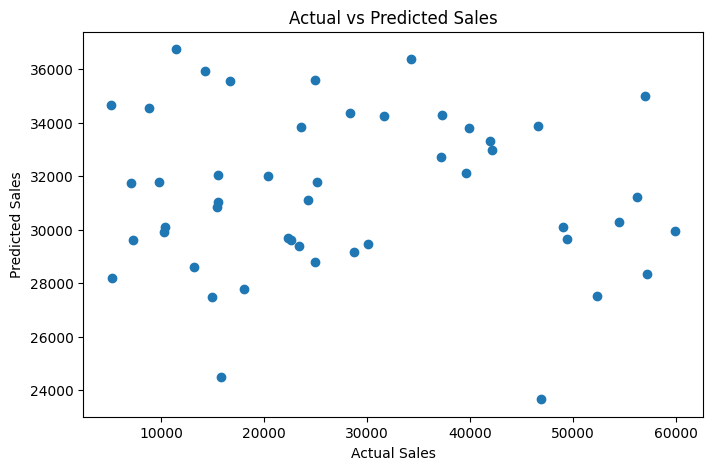

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()

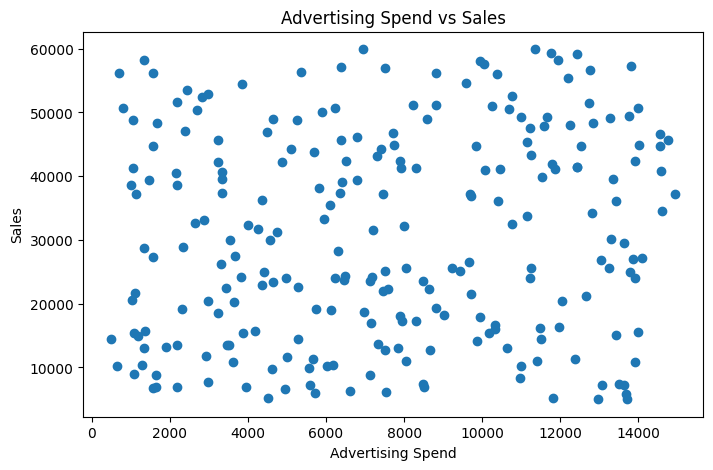

In [19]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Advertising_Spend'],
    df['Sales']
)

plt.xlabel("Advertising Spend")
plt.ylabel("Sales")

plt.title("Advertising Spend vs Sales")

plt.show()

Average Sales by Platform:
Facebook      27511.328125
Google Ads    32478.814815
Instagram     31002.636364
YouTube       32113.686567
dtype: float64


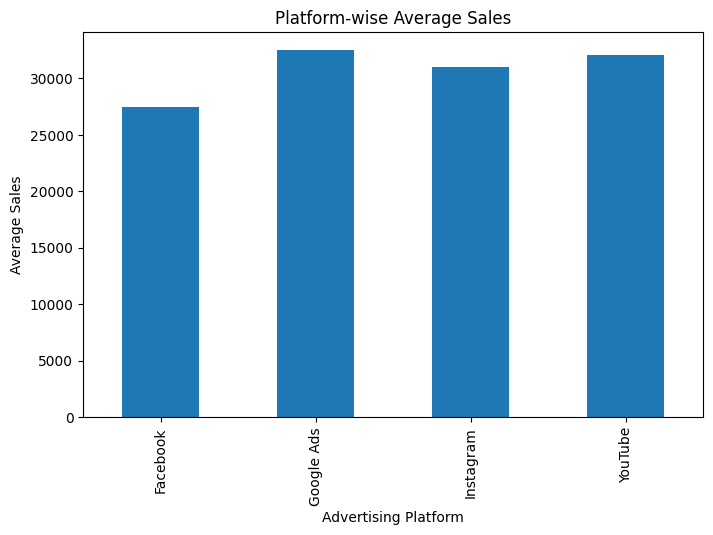

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

platform_sales = pd.Series({
    'Facebook': df.loc[
        (df['Platform_Google Ads'] == 0) &
        (df['Platform_Instagram'] == 0) &
        (df['Platform_YouTube'] == 0), 'Sales'
    ].mean(),

    'Google Ads': df.loc[df['Platform_Google Ads'] == 1, 'Sales'].mean(),

    'Instagram': df.loc[df['Platform_Instagram'] == 1, 'Sales'].mean(),

    'YouTube': df.loc[df['Platform_YouTube'] == 1, 'Sales'].mean()
})

print("Average Sales by Platform:")
print(platform_sales)

platform_sales.plot(kind='bar', figsize=(8, 5),
                    title='Platform-wise Average Sales')

plt.xlabel("Advertising Platform")
plt.ylabel("Average Sales")
plt.show()

In [22]:
print("BUSINESS INSIGHTS")

print("\n1. Average Sales:")
print(round(df['Sales'].mean(), 2))

print("\n2. Highest Sales:")
print(round(df['Sales'].max(), 2))

print("\n3. Lowest Sales:")
print(round(df['Sales'].min(), 2))

print("\n4. Advertising Spend and Sales Correlation:")
print(round(df['Advertising_Spend'].corr(df['Sales']), 2))

BUSINESS INSIGHTS

1. Average Sales:
30713.93

2. Highest Sales:
59917

3. Lowest Sales:
5009

4. Advertising Spend and Sales Correlation:
0.12


In [23]:
print("PROJECT CONCLUSION")

print("1. Sales data was successfully created and analyzed.")
print("2. Missing values were handled.")
print("3. Categorical data was transformed.")
print("4. Linear Regression model was trained.")
print("5. Future sales prediction was demonstrated.")
print("6. Advertising spend and sales were analyzed.")
print("7. Business insights were generated.")

print("\nSales Prediction Project Completed Successfully!")

PROJECT CONCLUSION
1. Sales data was successfully created and analyzed.
2. Missing values were handled.
3. Categorical data was transformed.
4. Linear Regression model was trained.
5. Future sales prediction was demonstrated.
6. Advertising spend and sales were analyzed.
7. Business insights were generated.

Sales Prediction Project Completed Successfully!
